#  Feature selection(QSAR Classification)





In [ ]:
#@title Installation of packages

!pip3 uninstall -y scikit-learn eli5
!pip3 install scikit-learn
!pip3 install eli5
!pip3 install rdkit==2023.9.4

Found existing installation: scikit-learn 1.8.0
Uninstalling scikit-learn-1.8.0:
  Successfully uninstalled scikit-learn-1.8.0
Found existing installation: eli5 0.16.0
Uninstalling eli5-0.16.0:
  Successfully uninstalled eli5-0.16.0
  Using cached scikit_learn-1.8.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (11 kB)
Using cached scikit_learn-1.8.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (8.9 MB)
  Using cached eli5-0.16.0-py2.py3-none-any.whl.metadata (18 kB)
Using cached eli5-0.16.0-py2.py3-none-any.whl (108 kB)


In [ ]:
import os

## Modify and uncomment the appropiate lines below to mark the right path to the folder where all the files are going to be stored

# if you upload your files directly, decomment next line:
# PATH = "/content/"

# if you use GoogleDrive, decomment next lines (You will need to give permission to Colab to access your Drive account):
# from google.colab import drive
# drive.mount('/content/drive')
# PATH = "/content/drive/MyDrive/PQSAR_Python_Course/" # Here we added a folder name where all the data is going to be stored in the google drive

PATH = "/content/sample_data/" # Corrected path based on kernel state

## Upload the file Earthworm_acute_toxicity_Train_imputed_scaled.csv to your folder and check whether it exists

os.path.isfile(PATH+'Earthworm_acute_toxicity_Train_imputed_scaled.csv')

True

To begin, execute a notebook cell to import the basic modules we will use and to define constants that will be needed later. Please modify the following cell if required and then execute it.


In [ ]:
#@title Import the required packages
import pandas as pd

In [ ]:
#@title Open the scaled descriptor files for training and test
import pandas as pd

df_train_for_selection = pd.read_csv(PATH + 'Earthworm_acute_toxicity_Train_imputed_scaled.csv', sep = ',', engine='python')
df_test_for_selection = pd.read_csv(PATH + 'Earthworm_acute_toxicity_Test_imputed_scaled.csv', sep = ',', engine='python')

You can check the sizes and columns of the tables to make sure you are working with the appropriate files.

In [ ]:
#@title Check the files
print("df_train_for_selection shape:", df_train_for_selection.shape)
print("df_test_for_selection shape:", df_test_for_selection.shape)
print("df_train_for_selection columns:\n", df_train_for_selection.columns)
print("df_test_for_selection columns:\n", df_test_for_selection.columns)

df_train_for_selection shape: (86, 1665)
df_test_for_selection shape: (38, 1665)
df_train_for_selection columns:
 Index(['SMILES', 'y', 'MaxAbsEStateIndex', 'MaxEStateIndex',
       'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt',
       'HeavyAtomMolWt',
       ...
       'SRW10', 'TSRW10', 'MW', 'AMW', 'WPath', 'WPol', 'Zagreb1', 'Zagreb2',
       'mZagreb1', 'mZagreb2'],
      dtype='object', length=1665)
df_test_for_selection columns:
 Index(['SMILES', 'y', 'MaxAbsEStateIndex', 'MaxEStateIndex',
       'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt',
       'HeavyAtomMolWt',
       ...
       'SRW10', 'TSRW10', 'MW', 'AMW', 'WPath', 'WPol', 'Zagreb1', 'Zagreb2',
       'mZagreb1', 'mZagreb2'],
      dtype='object', length=1665)


## Section 2: Unsupervised feature reduction

To begin, store the descriptors, SMILES, and y columns from the training dataset in three separate variables by selecting the appropriate columns.

In [ ]:
#@title Assignment of variables for SMILES, y, and descriptors
df_descriptors = df_train_for_selection.iloc[:,2:] # Assuming SMILES and y are the first two columns
df_smiles = df_train_for_selection['SMILES']
df_y = df_train_for_selection['y']

In [ ]:
#@title Remove infinite descriptors
import numpy as np

finite_cols = np.isfinite(df_descriptors).all()

print("shape of the dataframe before: ", df_descriptors.shape)
if sum(finite_cols) < len(df_descriptors.columns):
    print("There are infinites, and have been eliminated")
    booleans = list(finite_cols)
    to_drop = []
    for i,boolean in enumerate(booleans):
        if boolean == False:
            to_drop.append(i)
    df_descriptors = df_descriptors.drop(df_descriptors.columns[to_drop], axis=1)
else:
    print("There are no infinites")

print("shape of the dataframe after: ", df_descriptors.shape)

shape of the dataframe before:  (86, 1663)
There are no infinites
shape of the dataframe after:  (86, 1663)


In [ ]:
#@title Remove constant descriptors
uniq_cols = df_descriptors.nunique(axis=0, dropna=True)

print("shape of the dataframe before: ", df_descriptors.shape)

if any(ele == 1 for ele in list(uniq_cols)):
    print("There are columns with one unique value, and have been eliminated")
    to_drop = []
    for i, col in enumerate(uniq_cols):
        if col == 1:
            to_drop.append(df_descriptors.columns[i]) # Append column name instead of index
    df_descriptors = df_descriptors.drop(columns=to_drop)
else:
    print("There are no columns with one unique value")

print("shape of the dataframe after: ", df_descriptors.shape)

shape of the dataframe before:  (86, 1663)
There are columns with one unique value, and have been eliminated
shape of the dataframe after:  (86, 180)


In [ ]:
display(df_descriptors.head())
print(f"Current shape of df_descriptors: {df_descriptors.shape}")

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_piperdine,fr_pyridine,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiophene,fr_unbrch_alkane,fr_urea
0,-0.228088,-0.228088,-0.356370,0.891711,0.045771,-0.627098,-1.672444,-1.655258,-1.670367,-1.642990,...,-0.154303,-0.388276,-0.220863,-0.320256,-0.108465,-0.108465,-0.108465,-0.108465,-0.131899,-0.362738
1,-2.768083,-2.768083,2.459976,1.330501,0.381869,-0.549745,-1.121324,-1.094976,-1.118545,-1.002670,...,-0.154303,-0.388276,-0.220863,-0.320256,-0.108465,-0.108465,-0.108465,-0.108465,-0.131899,-0.362738
2,1.124221,1.124221,-0.891063,0.724365,1.034446,-0.173354,0.463498,0.389414,0.466242,0.704848,...,-0.154303,2.180319,-0.220863,-0.320256,-0.108465,-0.108465,-0.108465,-0.108465,-0.131899,-0.362738
3,0.182414,0.182414,0.509075,-0.305236,0.186973,-0.372676,0.306721,0.342079,0.303713,-0.148911,...,-0.154303,-0.388276,-0.220863,-0.320256,-0.108465,-0.108465,-0.108465,-0.108465,-0.131899,-0.362738
4,1.052710,1.052710,-0.761426,0.085969,0.925125,-0.187036,-0.359616,-0.327065,-0.356710,-0.255631,...,-0.154303,-0.388276,-0.220863,-0.320256,-0.108465,-0.108465,-0.108465,-0.108465,-0.131899,-0.362738


Current shape of df_descriptors: (86, 180)


Once the constant descriptors have been removed, your DataFrame should contain fewer descriptors.

In [ ]:
#@title Detect missing descriptors
missing_threshold = 0.00000000001

missing_series = df_descriptors.isnull().sum() / df_descriptors.shape[0]
print("shape of the dataframe before: ", df_descriptors.shape)
if any(ele > missing_threshold for ele in list(missing_series)):
    print("There are empty descriptors, and have been eliminated")
    to_drop = []
    for i, col in enumerate(missing_series):
        if col > missing_threshold:
            to_drop.append(df_descriptors.columns[i])
    df_descriptors = df_descriptors.drop(columns=to_drop)
else:
    print("There are no empty descriptors")

print("shape of the dataframe after: ", df_descriptors.shape)

shape of the dataframe before:  (86, 180)
There are no empty descriptors
shape of the dataframe after:  (86, 180)


Finally, we will identify which of the remaining descriptors are **correlated descriptors**. This means finding descriptors that are collinear, using a correlation coefficient threshold of 0.9 between features. For each correlated pair, only one descriptor will be removed.

Run the next cell to eliminate the correlated descriptors. This step may take a couple of minutes to complete.

In [ ]:
#@title Remove correlated descriptors
correl_threshold = 0.9

def correlation(dataset, threshold):
    col_corr = set() # Set of all the names of deleted columns

    # Identify non-numeric columns to exclude from correlation calculation
    # These are typically 'SMILES' and 'y' which are identifiers/targets, not descriptors
    non_numeric_cols_to_exclude = ['SMILES', 'y']

    # Create a temporary DataFrame with only numeric columns for correlation calculation
    # Drop columns that are specified to be excluded, if they exist
    numeric_dataset_for_corr = dataset.drop(columns=[col for col in non_numeric_cols_to_exclude if col in dataset.columns], errors='ignore')

    # Ensure all remaining columns are numeric; .corr() will only work on numbers
    numeric_dataset_for_corr = numeric_dataset_for_corr.select_dtypes(include=['number'])

    corr_matrix = numeric_dataset_for_corr.corr().abs()

    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if (corr_matrix.iloc[i, j] >= threshold) and (corr_matrix.columns[j] not in col_corr):
                colname = corr_matrix.columns[i] # getting the name of column
                col_corr.add(colname)

    # Drop the identified correlated columns from the *original* dataset
    # This ensures non-numeric columns like SMILES/y are not accidentally dropped
    columns_to_drop_from_original = [col for col in col_corr if col in dataset.columns]
    if columns_to_drop_from_original:
        dataset = dataset.drop(columns=columns_to_drop_from_original)

    return dataset

print("shape of the dataframe before: ", df_descriptors.shape)

df_descriptors = correlation(df_descriptors.copy(), correl_threshold)

print("shape of the dataframe after: ", df_descriptors.shape)

shape of the dataframe before:  (86, 180)
shape of the dataframe after:  (86, 142)


Now we need to add the `SMILES` and `y` columns back into the resulting DataFrame, filter the test DataFrame so that it contains the same columns, and then save both datasets.

In [ ]:
#@title Join filtered descriptors with SMILES and endpoint values

# Ensure SMILES and y are not already in df_descriptors before inserting
if 'SMILES' in df_descriptors.columns:
    df_descriptors = df_descriptors.drop(columns=['SMILES'])
if 'y' in df_descriptors.columns:
    df_descriptors = df_descriptors.drop(columns=['y'])

df_descriptors.insert(0,'SMILES',df_smiles) #Insert the SMILES column retrieved earlier
df_descriptors.insert(1,'y',df_y) #Insert the y column retrieved earlier

df_descriptors.to_csv(PATH + 'Earthworm_acute_toxicity_Train_descriptors_elimination.csv', index=False, sep=';') #Save as CSV file Earthworm_acute_toxicity_Train_descriptors_elimination.csv

train_columns = df_descriptors.columns #Retrieve column names from the reduced descriptors matrix in the training set you just saved

df_test_filtered = df_test_for_selection[train_columns] #Filter the test DataFrame by the columns present in the training DataFrame

df_test_filtered.to_csv(PATH + 'Earthworm_acute_toxicity_Test_descriptors_elimination.csv', index=False, sep=';') #Save as CSV file Earthworm_acute_toxicity_Test_descriptors_elimination.csv

###**Q1.** How many descriptors do you have after unsupervised feature selection?

Remember to enter the response in the platform.

In [ ]:
#WRITE YOUR CODE HERE TO RESPOND Q1
num_descriptors = df_descriptors.shape[1] - 2 # Subtract 'SMILES' and 'y' columns
print(f"After unsupervised feature selection, there are {num_descriptors} descriptors.")

After unsupervised feature selection, there are 142 descriptors.


In [ ]:
print(df_test_filtered.shape)
print(df_descriptors.shape)

(38, 144)
(86, 144)


## Section 3: Supervised feature selection



### Recursive Feature Elimination (RFE) algorithm

Once we have cleaned and split our dataset into training and test sets, we can proceed to select the most meaningful features for building a model that predicts our output variable. We will begin with a method called Recursive Feature Elimination (RFE). For more details on how it works, see the scikit-learn [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html).


RFE is a method that can use different estimators as a basis to rank and select features. These estimators are supervised learning methods that provide information about feature importance. We will learn more about these methods in the next practical session. For now, it is important to remember that the choice of estimator should match the type of model we plan to build.

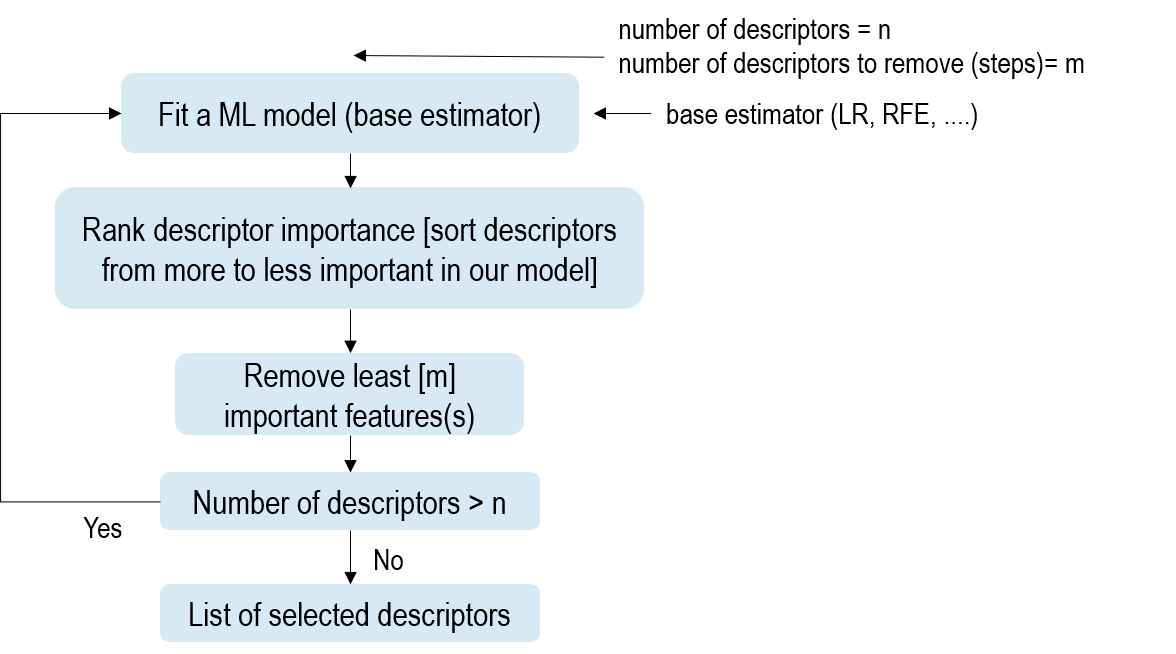


We will start by selecting features with `RFE`, using [Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) as the base estimator.

In [ ]:
#@title Example of RFE
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression


#Read the training set and separate the descriptors array and the output variable
df_train = pd.read_csv(PATH + "Earthworm_acute_toxicity_Train_descriptors_elimination.csv", sep = ';')

X = df_train.iloc[:,2:]
y = df_train.pop("y")

estimator = LogisticRegression(random_state=2023)

#Establish the number of features to select. Start with 5 features
num_features = 5
#Instantiate the RFE selector
selector = RFE(estimator, n_features_to_select=num_features, step=1)
#Fit the RFE selector to the training data
selector = selector.fit(X,y)

#Subset the descriptors DataFrame
feats_train_rfe1 = X.loc[:, selector.support_]
#Join the selected descriptors with the output variable and the SMILES column
df_train_rfe1 = pd.concat([df_train.SMILES, y, feats_train_rfe1], axis=1)

#Read the test set and select only the descriptor columns of interest
df_test = pd.read_csv(PATH + "Earthworm_acute_toxicity_Test_descriptors_elimination.csv", sep = ';')
descr_test = df_test.loc[:,list(feats_train_rfe1.columns)]
df_test_rfe1 = pd.concat([df_test.loc[:,["SMILES","y"]], descr_test], axis=1)

#Save both datasets as CSV files. Do not change the names, as they are used later
df_train_rfe1.to_csv("Earthworm_acute_toxicity_Train_RFE_logreg_nonupdated.csv", index=False)
df_test_rfe1.to_csv("Earthworm_acute_toxicity_Test_RFE_logreg_nonupdated.csv", index=False)

print("The features selected are:")
for feat in list(feats_train_rfe1.columns):
    print("\n",feat)

The features selected are:

 BCUT2D_MRHI

 PEOE_VSA4_rdk

 PEOE_VSA9_rdk

 SMR_VSA2_rdk

 SlogP_VSA8_rdk


###**Q2.** Which are the features selected using this approach?

Select the correct options in the question.

As you saw in the code above, we chose an arbitrary number of features, which was five in our case. It is important to keep in mind that there is a limit to the ratio of features to molecules.

Ideally, you should use no more than one feature for every five molecules in the training dataset. Check what the maximum number of features should be in our case.

In [ ]:
#@title Calculate the maximum number of features
#WRITE YOUR CODE HERE

# Assuming df_train is available from the previous RFE example cell
# Number of molecules in the training dataset (rows)
num_molecules_train = X.shape[0]

# Calculate maximum number of features based on the rule
max_num_features = num_molecules_train // 5

print("The maximum number of features to use is: ", str(max_num_features))

The maximum number of features to use is:  17


You can choose a different number of features if you want to experiment. Reuse the code in the following cell and try to obtain a different amount. Remember to change the file name so that it is not overwritten, as you will need these files for the next practical session.


In [ ]:
#@title RFE with more features.
#WRITE YOUR CODE HERE

In the following cell, complete the code to use a Decision Tree estimator to select five features with RFE. For the base estimator, we will use the default hyperparameters in most cases, except for the random_state.

As with the dataset split, randomness can cause problems for reproducibility. For this reason, we will use a seed value of 2023 in all steps that involve randomness throughout this course.

[Here](https://scikit-learn.org/stable/modules/tree.html) is the relevant documentation for reference.

In [ ]:
#@title RFE with Decision Tree

from sklearn.feature_selection import RFE
#Import the correct package
from sklearn.tree import DecisionTreeClassifier

#Read the training set and separate the descriptors array and the output variable
df_train = pd.read_csv(PATH + "Earthworm_acute_toxicity_Train_descriptors_elimination.csv", sep = ';')
X = df_train.iloc[:,2:]
y = df_train.pop("y")

estimator = DecisionTreeClassifier(random_state=2023)

#Establish the number of features to select. Start with 5 features
num_features = 5
#Instantiate the RFE selector
selector = RFE(estimator, n_features_to_select=num_features, step=1)
#Fit the RFE selector to the training data
selector = selector.fit(X,y)

#Subset the descriptors DataFrame
feats_train_rfe2 = X.loc[:, selector.support_]
#Join the selected descriptors with the output variable and the SMILES column
df_train_rfe2 = pd.concat([df_train.SMILES, y, feats_train_rfe2], axis=1)

#Read the test set and select only the descriptor columns of interest
df_test = pd.read_csv(PATH + "Earthworm_acute_toxicity_Test_descriptors_elimination.csv", sep = ';')
descr_test = df_test.loc[:,list(feats_train_rfe2.columns)]
df_test_rfe2 = pd.concat([df_test.loc[:,["SMILES","y"]], descr_test], axis=1)

#Save both datasets as CSV files
df_train_rfe2.to_csv("Earthworm_acute_toxicity_Train_RFE_dectree_nonupdated.csv", index=False)
df_test_rfe2.to_csv("Earthworm_acute_toxicity_Test_RFE_dectree_nonupdated.csv", index=False)

print("The features selected are:")
for feat in list(feats_train_rfe2.columns):
    print("\n",feat)

The features selected are:

 MolWt

 BCUT2D_MRHI

 PEOE_VSA8_rdk

 PEOE_VSA9_rdk

 EState_VSA3_rdk


### Permutation Importance (PI) algorithm
Let’s try another method for feature selection: Permutation Importance (PI). For more information on how it works, see the [documentation](https://eli5.readthedocs.io/en/latest/blackbox/permutation_importance.html).

As you can see, this method is also based on a supervised learning algorithm, which acts as the estimator to determine the importance of each feature.

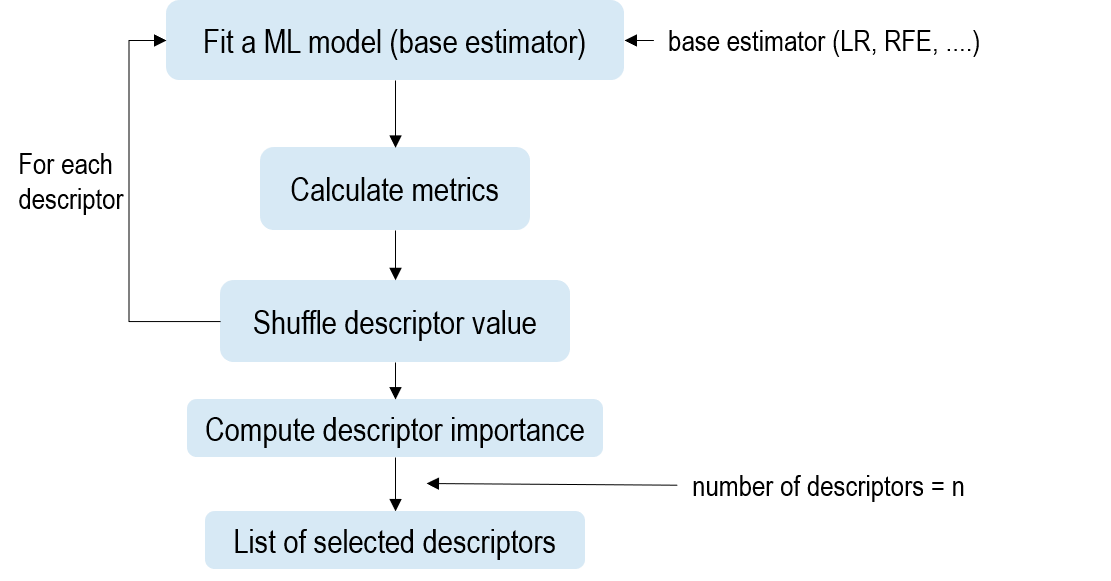









In this case, we will use a different package, eli5, as shown in the third import line of the code. This package is not included by default in Google Colab, so it first needs to be installed. We did this earlier, but if you encounter any issues you can revisit the cell in the preliminary section and reinstall it.

With Permutation Importance, we will use Logistic Regression as the base estimator, just as we did previously with RFE. Review the following code and run the cell to obtain the feature importances.

Since Permutation Importance relies on randomness to shuffle the descriptor values, it is advisable to set a `random_state` to ensure reproducibility. In this course, we will use `2023`.

In [ ]:
import pandas as pd
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from eli5.sklearn import PermutationImportance

# Define PATH to ensure file access
PATH = "/content/sample_data/"

# Read the training set and separate descriptors and target
df_train = pd.read_csv(PATH + "Earthworm_acute_toxicity_Train_descriptors_elimination.csv", sep=';')

X = df_train.iloc[:, 2:]
y = df_train["y"]

# Create and fit logistic regression model
estimator = LogisticRegression(max_iter=1000, random_state=2023)
estimator.fit(X, y)

# Compute permutation importance
perm = PermutationImportance(estimator, random_state=2023)
perm.fit(X, y)

# Select features with importance >= 0.01
sel = SelectFromModel(perm, threshold=0.01, prefit=True)

# Get selected feature names
selected_features = X.columns[sel.get_support()]

# Create dataframe of all features and importances
dataframe_permutation = pd.DataFrame({
    'feature': X.columns,
    'importance': perm.feature_importances_
})

dataframe_permutation_ordered = dataframe_permutation.sort_values(
    by='importance',
    ascending=False
)

print(dataframe_permutation_ordered)
print("\nSelected features:")
print(list(selected_features))

               feature  importance
37       PEOE_VSA4_rdk    0.051163
45        SMR_VSA2_rdk    0.041860
60      SlogP_VSA8_rdk    0.034884
111  fr_Ndealkylation2    0.032558
71     EState_VSA8_rdk    0.032558
..                 ...         ...
130         fr_oxazole    0.000000
129           fr_nitro    0.000000
126          fr_ketone    0.000000
135       fr_sulfonamd    0.000000
138       fr_tetrazole    0.000000

[142 rows x 2 columns]

Selected features:
['qed', 'SPS', 'MaxPartialCharge', 'FpDensityMorgan3', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'Ipc', 'PEOE_VSA11_rdk', 'PEOE_VSA13_rdk', 'PEOE_VSA3_rdk', 'PEOE_VSA4_rdk', 'PEOE_VSA5_rdk', 'PEOE_VSA7_rdk', 'SMR_VSA2_rdk', 'SMR_VSA4_rdk', 'SlogP_VSA11_rdk', 'SlogP_VSA2_rdk', 'SlogP_VSA8_rdk', 'EState_VSA2_rdk', 'EState_VSA7_rdk', 'EState_VSA8_rdk', 'VSA_EState2_rdk', 'VSA_EState5_rdk', 'VSA_EState7_rdk', 'VSA_EState8_rdk', 'VSA_EState9_rdk', 'NumAliphaticHeterocycles', 'NumHAcceptors', 'NumRotatableBonds',

Check the importance values in the printed DataFrame. Based on these results, how many descriptors would you choose to build a model?

**Note:** Do not worry if this method does not identify any important features. This behaviour is normal, although undesirable. Such a result suggests that this base estimator is not well suited to the method.

You can still choose a number of features and assign it to the variable `pi_n_feats` so that we can select them and save them in a CSV file. However, we will not use this method in the next part, as the PI values are not adequate.

In [ ]:
#@title Selection of the number of features and saving the files
!pip install eli5 # Install eli5 to ensure it's available
import pandas as pd
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from eli5.sklearn import PermutationImportance

PATH = "/content/sample_data/" # Define PATH to ensure file access

# Read the training set and separate descriptors and target (re-do from 009cb592 to ensure context)
df_train = pd.read_csv(PATH + "Earthworm_acute_toxicity_Train_descriptors_elimination.csv", sep=';')
X = df_train.iloc[:, 2:]
y = df_train["y"]

# Create and fit logistic regression model (re-do from 009cb592 to ensure context)
estimator = LogisticRegression(max_iter=1000, random_state=2023)
estimator.fit(X, y)

# Compute permutation importance (re-do from 009cb592 to ensure context)
perm = PermutationImportance(estimator, random_state=2023)
perm.fit(X, y)

# Create dataframe of all features and importances (re-do from 009cb592 to ensure context)
dataframe_permutation = pd.DataFrame({
    'feature': X.columns,
    'importance': perm.feature_importances_
})

dataframe_permutation_ordered = dataframe_permutation.sort_values(
    by='importance',
    ascending=False
)


#Insert the number of features to select here

pi_n_feats = 5


#Subset the descriptors DataFrame
feat_select_pi = list(dataframe_permutation_ordered.iloc[:pi_n_feats,0])
feats_train_pi1 = X.loc[:,feat_select_pi]

#Join the selected descriptors with the output variable and the SMILES column
df_train_pi1 = pd.concat([df_train.SMILES, y, feats_train_pi1], axis=1)

#Read the test set and select only the descriptor columns of interest
df_test = pd.read_csv(PATH + "Earthworm_acute_toxicity_Test_descriptors_elimination.csv", sep = ';')

# Store SMILES and y for concatenation later, without altering df_test's structure
smiles_test = df_test['SMILES']
y_test = df_test['y']

descr_test = df_test.loc[:,list(feats_train_pi1.columns)]
df_test_pi1 = pd.concat([smiles_test, y_test, descr_test], axis=1)

#Save both datasets as csv files
df_train_pi1.to_csv("Earthworm_acute_toxicity_Train_PI_logreg_nonupdated.csv", index=False, sep = ';')
df_test_pi1.to_csv("Earthworm_acute_toxicity_Test_PI_logreg_nonupdated.csv", index=False, sep = ';')

print("The features selected are:")
for feat in list(feats_train_pi1.columns):
    print("\n",feat)

The features selected are:

 PEOE_VSA4_rdk

 SMR_VSA2_rdk

 SlogP_VSA8_rdk

 fr_Ndealkylation2

 EState_VSA8_rdk


Let’s now try the Decision Tree algorithm as the estimator, as we did earlier with RFE. Fill in the gaps in the following code and run the cell to obtain the feature importances.

In [ ]:
#@title Permutation Importance with Decision Tree
from sklearn.feature_selection import SelectFromModel
from eli5.sklearn import PermutationImportance
#Import the correct package
from sklearn.tree import DecisionTreeClassifier


#Read the training set and separate the descriptors array and the output variable
df_train = pd.read_csv(PATH + "Earthworm_acute_toxicity_Train_descriptors_elimination.csv", sep = ';')
X = df_train.iloc[:,2:]
y = df_train.pop("y")

estimator = DecisionTreeClassifier(random_state=2023)

estimator.fit(X, y)
perm = PermutationImportance(estimator, random_state=2023).fit(X, y)

#Use the attribute perm.feature_importances_ for feature selection
#Select features that increase accuracy by at least 0.01
sel = SelectFromModel(perm, threshold=0.01, prefit=True)

#Get the features and their importances in a DataFrame, and sort them to see which are most important
importances_ = list(perm.feature_importances_)
features__permutation = list(X.columns)

dataframe_permutation = pd.DataFrame({
                            'feature' : features__permutation,
                            'importance' : importances_},
                            columns=['feature','importance'])

dataframe_permutation_ordered = dataframe_permutation.sort_values('importance',ascending=False)

print(dataframe_permutation_ordered)

               feature  importance
42       PEOE_VSA9_rdk    0.179070
84           NHOHCount    0.125581
5                MolWt    0.116279
16         BCUT2D_MRHI    0.109302
41       PEOE_VSA8_rdk    0.106977
..                 ...         ...
137  fr_term_acetylene    0.000000
138       fr_tetrazole    0.000000
139       fr_thiophene    0.000000
140   fr_unbrch_alkane    0.000000
141            fr_urea    0.000000

[142 rows x 2 columns]


In this case, you should see non-zero values in the first features. Run the next cell to display the feature importances in a bar plot, and use a visual approach to decide how many descriptors to keep.

<Axes: title={'center': 'Feature importances'}, ylabel='feature'>

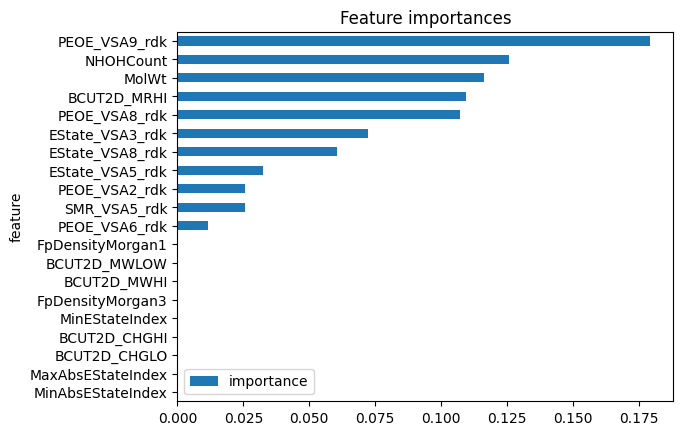

In [ ]:
#@title Graph to visualise feature importances
%matplotlib inline

import matplotlib.pyplot as plt

df_plot = dataframe_permutation_ordered.iloc[:20,:].sort_values('importance',ascending=True)

df_plot.plot(
    x="feature",
    kind = "barh",
    stacked = False,
    title = "Feature importances")


Based on this plot, how many descriptors would you choose to build a model? Remember that we previously calculated a limit based on the number of molecules in the training set. Is that a concern here?

Enter the number in the variable `pi_n_feats` so that we can select the descriptors and save them in a CSV file.


###**Q3.** How many descriptors with significant importance have you found?

Enter the value in the training platform and use it in the code below. In this case, we will consider significant all descriptors whose bar in the plot is visible.

In [ ]:
#@title Selection of features with Permutation Importance Decision Tree
#Insert the number of features to select here

pi_n_feats = 5


#Subset the descriptors DataFrame
feat_select_pi = list(dataframe_permutation_ordered.iloc[:pi_n_feats,0])
feats_train_pi1 = X.loc[:,feat_select_pi]

#Join the selected descriptors with the output variable and the SMILES column
df_train_pi1 = pd.concat([df_train.SMILES, y, feats_train_pi1], axis=1)

#Read the test set and select only the descriptor columns of interest
df_test = pd.read_csv(PATH + "Earthworm_acute_toxicity_Test_descriptors_elimination.csv", sep=';')
descr_test = df_test.loc[:,list(feats_train_pi1.columns)]
df_test_pi1 = pd.concat([df_test.loc[:,["SMILES","y"]], descr_test], axis=1)

#Save both datasets as csv files
df_train_pi1.to_csv("Earthworm_acute_toxicity_Train_PI_dectree_nonupdated.csv", index=False, sep = ';')
df_test_pi1.to_csv("Earthworm_acute_toxicity_Test_PI_dectree_nonupdated.csv", index=False, sep = ';')

print("The features selected are:")
for feat in list(feats_train_pi1.columns):
    print("\n",feat)

The features selected are:

 PEOE_VSA9_rdk

 NHOHCount

 MolWt

 BCUT2D_MRHI

 PEOE_VSA8_rdk


### Section 3: Update of the imputation and scaling

It is important to note that once we have selected a set of features, only these should be considered in the model. For this reason, it is necessary to reassess the imputation step. Previously, the criterion used to determine the most similar chemicals for averaging included all available descriptors. We will now repeat the imputation and standardisation procedures, but this time using only the selected features.

The aim is to repeat the imputation and standardisation steps on the datasets containing only the chosen descriptors.

We will create a function to perform this automatically for all DataFrames with the selected features. This function will:

1. Read the training and test DataFrames with the original descriptor values

2. Filter these DataFrames to keep only the selected descriptor columns

3. Fit the KNNImputer to the training DataFrame and transform both training and test DataFrames

4. Fit the scaler to the training DataFrame and transform both training and test DataFrames

As inputs, we will need:

* The original DataFrames

* A file with the filtered column names

In [ ]:
#@title Function to revise imputation and scaling


import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler


def imputer_scaler(df_target, df_reference, columns_descriptors):
    #Prepare the imputer and scaler objects
    imputer = KNNImputer(missing_values=np.nan, n_neighbors=3, weights="uniform")
    scaler = StandardScaler()

    print(columns_descriptors)

    reference_descriptors_matrix = df_reference[columns_descriptors]
    target_descriptors_matrix = df_target[columns_descriptors]
    imputer.fit(reference_descriptors_matrix)



    imputed_ref_matrix = imputer.transform(reference_descriptors_matrix)
    imputed_tag_matrix = imputer.transform(target_descriptors_matrix)



    scaler.fit(imputed_ref_matrix)


    imputed_scaled_tag_matrix = scaler.transform(imputed_tag_matrix)
    imputed_scaled_ref_matrix = scaler.transform(imputed_ref_matrix)
    df_imputed_scaled = pd.DataFrame(imputed_scaled_tag_matrix, columns = columns_descriptors)


    smiles_target = list(df_target['SMILES'])

    y_target = list(df_target['y'])

    df_imputed_scaled.insert(0,'SMILES',smiles_target)
    df_imputed_scaled.insert(1,'y',y_target)

    return df_imputed_scaled





You should now use this function to update the files created for the supervised methods. Keep in mind that the files required for the next lesson are the new ones created here, without the `_nonupdated` suffix.

In [ ]:
#@title Update csv files with selected features

combinations_algorithms_base_estimators = ['RFE_logreg', 'RFE_dectree','PI_dectree']

for combination in combinations_algorithms_base_estimators:
    print('processing ', combination)

    # Determine separator for _nonupdated files, as some are comma-separated and others semicolon-separated
    if combination.startswith('PI_'):
        sep_char_nonupdated = ';'
    else:
        sep_char_nonupdated = ','

    #Read the list of descriptors
    # The _nonupdated files were saved directly to /content/, not PATH, so remove PATH prefix here.
    file_with_descriptors = pd.read_csv('/content/Earthworm_acute_toxicity_Train_{}_nonupdated.csv'.format(combination), sep = sep_char_nonupdated)
    list_with_descriptors = file_with_descriptors.columns[2:]


    #Process untransformed training files using only the selected descriptors
    # NOTE: Original raw files (Earthworm_acute_toxicity_Train.csv and Test.csv) are not available.
    # Using 'Earthworm_acute_toxicity_Train_descriptors_elimination.csv' and 'Earthworm_acute_toxicity_Test_descriptors_elimination.csv'
    # as the 'original' input for re-imputation/scaling, as they are the closest available data before supervised selection.

    df_train_original = pd.read_csv(PATH + "Earthworm_acute_toxicity_Train_descriptors_elimination.csv", sep = ';')
    output_name_train =  'Earthworm_acute_toxicity_Train_{}.csv'.format(combination)
    final_train = imputer_scaler(df_train_original,df_train_original,list_with_descriptors)
    final_train.to_csv(output_name_train,index = False, sep = ';')

    #Process the test files
    df_test_original = pd.read_csv(PATH + "Earthworm_acute_toxicity_Test_descriptors_elimination.csv", sep = ';')
    output_name_test =  'Earthworm_acute_toxicity_Test_{}.csv'.format(combination)
    final_test = imputer_scaler(df_test_original,df_train_original,list_with_descriptors)
    final_test.to_csv(output_name_test,index = False, sep = ';')

    print('processed ', combination ,'\n')

processing  RFE_logreg
Index(['BCUT2D_MRHI', 'PEOE_VSA4_rdk', 'PEOE_VSA9_rdk', 'SMR_VSA2_rdk',
       'SlogP_VSA8_rdk'],
      dtype='object')
Index(['BCUT2D_MRHI', 'PEOE_VSA4_rdk', 'PEOE_VSA9_rdk', 'SMR_VSA2_rdk',
       'SlogP_VSA8_rdk'],
      dtype='object')
processed  RFE_logreg 

processing  RFE_dectree
Index(['MolWt', 'BCUT2D_MRHI', 'PEOE_VSA8_rdk', 'PEOE_VSA9_rdk',
       'EState_VSA3_rdk'],
      dtype='object')
Index(['MolWt', 'BCUT2D_MRHI', 'PEOE_VSA8_rdk', 'PEOE_VSA9_rdk',
       'EState_VSA3_rdk'],
      dtype='object')
processed  RFE_dectree 

processing  PI_dectree
Index(['PEOE_VSA9_rdk', 'NHOHCount', 'MolWt', 'BCUT2D_MRHI', 'PEOE_VSA8_rdk'], dtype='object')
Index(['PEOE_VSA9_rdk', 'NHOHCount', 'MolWt', 'BCUT2D_MRHI', 'PEOE_VSA8_rdk'], dtype='object')
processed  PI_dectree 



In [ ]:
import os
print(os.listdir('/content/'))

['.config', 'Earthworm_acute_toxicity_Train_RFE_logreg.csv', 'Earthworm_acute_toxicity_Train_PI_dectree_nonupdated.csv', 'Earthworm_acute_toxicity_Train_RFE_dectree.csv', 'Earthworm_acute_toxicity_Test_RFE_dectree.csv', 'Earthworm_acute_toxicity_Test_PI_dectree.csv', 'Earthworm_acute_toxicity_Train_PI_logreg_nonupdated.csv', 'Earthworm_acute_toxicity_Train_PI_dectree.csv', 'Earthworm_acute_toxicity_Test_RFE_logreg_nonupdated.csv', 'Earthworm_acute_toxicity_Train_RFE_logreg_nonupdated.csv', 'Earthworm_acute_toxicity_Test_PI_logreg_nonupdated.csv', 'Earthworm_acute_toxicity_Test_PI_dectree_nonupdated.csv', 'Earthworm_acute_toxicity_Test_RFE_logreg.csv', 'Earthworm_acute_toxicity_Test_RFE_dectree_nonupdated.csv', 'Earthworm_acute_toxicity_Train_RFE_dectree_nonupdated.csv', 'sample_data']


In [ ]:
from google.colab import files

file_to_download = 'Earthworm_acute_toxicity_Test_RFE_logreg.csv'
files.download(file_to_download)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download the files. You may need to refresh the file list to see them appear before downloading.

### Download all updated CSV files

Here are the updated CSV files generated after the feature selection, re-imputation, and scaling steps. You can download them using the code below. You may need to refresh the file list in the Colab sidebar to see them appear before downloading.